# 04c · Chronos-2 Fine-Tuned on Walmart Data

**Owner:** Max · **Reads:** notebook 01 outputs, `chronos2_zs` forecasts from 04a · **Feeds:** 05 (scoring)

**The question:** does adapting Chronos-2 to our Walmart sales beat using it as-is (zero-shot)?
This is the professor's "go beyond zero-shot" note answered directly. It is a **timeboxed experiment**: if it isn't
producing results by Sat Nov 21, it moves to the future-work slide.

**How it works**
- For each window, we start from the pretrained Chronos-2 and train it a little more on every product's sales
  history **before that window starts**. The model never sees the window's actual sales (same no-peeking rule as everything else).
- We use **LoRA**: instead of changing all ~120M weights, it trains a small add-on (well under 1% of the size).
  Faster, fits on a free T4, and less likely to forget what the model already knows.
- Then the fine-tuned copy forecasts the window exactly like 04a's zero-shot run (sales history only; covariates didn't help Chronos-2).

| Model name in files | What it is |
|---|---|
| `chronos2_ft` | Chronos-2 + LoRA fine-tuning on our sales history, retrained for each window |

**Windows:** `val_1`, `val_2`, `test` by default (enough for 05 to score it). Backtests are optional (see Settings).

**Output:** `data/forecasts/chronos2_ft_<window>.parquet`, same columns as 04a (`forecast` = median, `mean`, `q0.1 … q0.9`), so 05 scores it automatically.

**Runtime:** **Runtime → Change runtime type → T4 GPU.** Run with `SAMPLE = True` first (100 products, short training) to make sure it works,
then `SAMPLE = False`. Finished windows are skipped if Colab disconnects.

## 0 · Settings

In [10]:
SAMPLE      = False       # True = 100-product smoke test with short training; False = all ~12,200 California series
WINDOWS     = ["val_1", "val_2", "test"]   # add "bt_4", "bt_3", "bt_2", "bt_1" only if we later want it in 06's calibration/ensemble
OVERWRITE   = False      # True = redo windows that already have a forecast file

# Fine-tuning settings (LoRA). The library recommends a learning rate around 1e-5 for LoRA.
FINETUNE_MODE = "lora"
LEARNING_RATE = 1e-5
NUM_STEPS     = 50 if SAMPLE else 1000   # training steps per window
TRAIN_BATCH   = 64       # series per training step; lowered automatically if the GPU runs out of memory
PRED_BATCH    = 128      # series per forecasting batch
SEED          = 42

DRIVE_DIR   = "/content/drive/MyDrive/AML_Term_Project"
DATA_DIR    = f"{DRIVE_DIR}/data"
OUT_DIR     = f"{DATA_DIR}/forecasts_sample" if SAMPLE else f"{DATA_DIR}/forecasts"
CKPT_DIR    = "/content/chronos2_ft_ckpt"   # local scratch for checkpoints (not saved to Drive)

MODEL_ID    = "amazon/chronos-2"
MODEL_NAME  = "chronos2_ft"
QUANTILES   = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]

## 1 · Install and connect

In [11]:
!pip install -q "chronos-forecasting==2.3.2" "peft>=0.18.1,<1" accelerate   # peft = LoRA; accelerate = training loop
# Colab ships an old torchao that makes peft refuse to load. We don't use torchao, so remove it.
!pip uninstall -y -q torchao

In [12]:
import os, json, time, gc
import numpy as np
import pandas as pd
import torch

try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    print("Not running in Colab: using the paths in Settings as-is.")

os.makedirs(OUT_DIR, exist_ok=True)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE, "| torch", torch.__version__)
if DEVICE == "cpu":
    print("WARNING: no GPU found. Set Runtime -> Change runtime type -> T4 GPU. Fine-tuning on CPU is very slow.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Device: cuda | torch 2.14.1+cu130


## 2 · Load data and windows (same window list as every notebook)

In [13]:
df = pd.read_parquet(f"{DATA_DIR}/{'ca_sample100' if SAMPLE else 'ca_sales'}.parquet", columns=["unique_id", "ds", "y"])
df["unique_id"] = df["unique_id"].astype(str)
df["ds"] = pd.to_datetime(df["ds"])
df = df.sort_values(["unique_id", "ds"]).reset_index(drop=True)

with open(f"{DATA_DIR}/windows.json") as f:
    wjson = json.load(f)
H = wjson["horizon"]

val1_start = pd.Timestamp(wjson["val_1"]["start"])
windows = {}
for k in range(4, 0, -1):
    start = val1_start - pd.Timedelta(days=H * k)
    windows[f"bt_{k}"] = (start, start + pd.Timedelta(days=H - 1))
for name in ["val_1", "val_2", "test"]:
    windows[name] = (pd.Timestamp(wjson[name]["start"]), pd.Timestamp(wjson[name]["end"]))
windows = {w: windows[w] for w in windows if w in WINDOWS}

print(f"{df['unique_id'].nunique():,} series, {len(df):,} rows")
pd.DataFrame({w: {"start": s.date(), "end": e.date()} for w, (s, e) in windows.items()}).T

12,196 series, 18,559,286 rows


,start,end
val_1,2016-02-29,2016-03-27
val_2,2016-03-28,2016-04-24
test,2016-04-25,2016-05-22


## 3 · Load pretrained Chronos-2

In [14]:
from chronos import Chronos2Pipeline
base = Chronos2Pipeline.from_pretrained(MODEL_ID, device_map=DEVICE)
print("Loaded", MODEL_ID)

Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]

Loaded amazon/chronos-2


## 4 · Fine-tune, then forecast, one window
For a window starting on day *S*:
1. **Training data** = each product's sales before *S*. The library cuts random 28-day "pretend forecasts" out of that history
   and nudges the model to predict them better. Products with less than 56 days of history are left out of training.
2. **Forecast** = the fine-tuned copy predicts the 28 window days from the same history, like 04a.
3. The fine-tuned copy is thrown away before the next window, so each window starts from the original pretrained model.

In [15]:
def finetune(start, batch_size=TRAIN_BATCH):
    hist = df[df["ds"] < start]
    train_series = [g.to_numpy(dtype="float32") for _, g in hist.groupby("unique_id", sort=False)["y"]]
    while True:
        try:
            torch.manual_seed(SEED)
            ft = base.fit(
                inputs=train_series,
                prediction_length=H,
                finetune_mode=FINETUNE_MODE,
                learning_rate=LEARNING_RATE,
                num_steps=NUM_STEPS,
                batch_size=batch_size,
                output_dir=CKPT_DIR,
                seed=SEED,
            )
            return ft, batch_size, len(train_series)
        except torch.cuda.OutOfMemoryError:
            gc.collect(); torch.cuda.empty_cache()
            batch_size //= 2
            print(f"  GPU out of memory while training -> retrying with batch_size={batch_size}")
            if batch_size < 4:
                raise


def forecast(pipe, wname, start, batch_size=PRED_BATCH):
    context = df[df["ds"] < start]
    while True:
        try:
            out = pipe.predict_df(
                context, id_column="unique_id", timestamp_column="ds", target="y",
                prediction_length=H, quantile_levels=QUANTILES, batch_size=batch_size,
            )
            break
        except torch.cuda.OutOfMemoryError:
            gc.collect(); torch.cuda.empty_cache()
            batch_size //= 2
            print(f"  GPU out of memory while forecasting -> retrying with batch_size={batch_size}")
            if batch_size < 4:
                raise
    res = pd.DataFrame({
        "unique_id": out["unique_id"].astype(str),
        "ds": pd.to_datetime(out["ds"]),
        "model": MODEL_NAME,
        "window": wname,
        "forecast": out["0.5"].clip(lower=0).astype("float32"),
        "mean": out["predictions"].clip(lower=0).astype("float32"),
    })
    for q in QUANTILES:
        res[f"q{q}"] = out[str(q)].clip(lower=0).astype("float32")
    return res

## 5 · Run every window (skips windows already saved)

In [16]:
log_rows = []
for wname, (start, end) in windows.items():
    path = f"{OUT_DIR}/{MODEL_NAME}_{wname}.parquet"
    if os.path.exists(path) and not OVERWRITE:
        print(f"skip  {MODEL_NAME} {wname:6s} (already saved)")
        continue
    t0 = time.time()
    ft, used_bs, n_train = finetune(start)
    t_fit = time.time() - t0
    res = forecast(ft, wname, start)
    res.to_parquet(path, index=False)
    secs = time.time() - t0
    n = res["unique_id"].nunique()
    print(f"done  {MODEL_NAME} {wname:6s} trained on {n_train:,} series, forecast {n:,}  "
          f"fit {t_fit/60:5.1f} min, total {secs/60:5.1f} min")
    if SAMPLE:
        print(f"      estimate for the full run: about {t_fit / 60 * 1000 / NUM_STEPS:.0f} min of training per window at 1,000 steps")
    log_rows.append({"model": MODEL_NAME, "window": wname, "series": n, "train_series": n_train,
                     "steps": NUM_STEPS, "lr": LEARNING_RATE, "mode": FINETUNE_MODE, "train_batch": used_bs,
                     "fit_minutes": round(t_fit / 60, 1), "total_minutes": round(secs / 60, 1),
                     "device": DEVICE, "sample": SAMPLE, "run_at": pd.Timestamp.now().strftime("%Y-%m-%d %H:%M")})
    del ft; gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()

if log_rows:
    log_path = f"{OUT_DIR}/run_log.csv"
    new = pd.DataFrame(log_rows)
    new.to_csv(log_path, mode="a", header=not os.path.exists(log_path), index=False)
    display(new)

Step,Training Loss
100,5.597111
200,5.646697
300,5.688970
400,5.749776
500,5.671101
600,5.679791
700,5.677869
800,5.673616
900,5.658450
1000,5.612893


done  chronos2_ft val_1  trained on 12,196 series, forecast 12,196  fit  23.5 min, total  25.9 min


Step,Training Loss
100,5.604474
200,5.717448
300,5.698244
400,5.657937
500,5.685733


Step,Training Loss
100,5.604474
200,5.717448
300,5.698244
400,5.657937
500,5.685733
600,5.726461
700,5.613881
800,5.701100
900,5.684432
1000,5.627064


done  chronos2_ft val_2  trained on 12,196 series, forecast 12,196  fit  23.5 min, total  26.0 min


Step,Training Loss
100,5.700482
200,5.752630
300,5.714993
400,5.672022
500,5.685319
600,5.662621
700,5.686581
800,5.690344
900,5.666097
1000,5.632879


done  chronos2_ft test   trained on 12,196 series, forecast 12,196  fit  23.8 min, total  26.3 min


,model,window,series,train_series,steps,lr,mode,train_batch,fit_minutes,total_minutes,device,sample,run_at
0,chronos2_ft,val_1,12196,12196,1000,0.00001,lora,64,23.5,25.9,cuda,False,2026-11-24 18:59
1,chronos2_ft,val_2,12196,12196,1000,0.00001,lora,64,23.5,26.0,cuda,False,2026-11-24 19:25
2,chronos2_ft,test,12196,12196,1000,0.00001,lora,64,23.8,26.3,cuda,False,2026-11-24 19:51


## 6 · Quick check: fine-tuned vs. zero-shot
Not the official evaluation (that's 05). Same products, same days, same windows, so the comparison is fair.
Negative change = fine-tuning helped. Also shows total forecast ÷ actual units (1.00 = right on total).

In [17]:
actual = df[["unique_id", "ds", "y"]]
rows = []
for wname in windows:
    p_ft, p_zs = f"{OUT_DIR}/{MODEL_NAME}_{wname}.parquet", f"{OUT_DIR}/chronos2_zs_{wname}.parquet"
    if not (os.path.exists(p_ft) and os.path.exists(p_zs)):
        print(f"{wname}: missing {'zero-shot' if os.path.exists(p_ft) else 'fine-tuned'} file, skipped")
        continue
    ft = pd.read_parquet(p_ft, columns=["unique_id", "ds", "forecast"])
    zs = pd.read_parquet(p_zs, columns=["unique_id", "ds", "forecast"])
    for f_ in (ft, zs):
        f_["unique_id"] = f_["unique_id"].astype(str); f_["ds"] = pd.to_datetime(f_["ds"])
    m = (ft.rename(columns={"forecast": "ft"})
           .merge(zs.rename(columns={"forecast": "zs"}), on=["unique_id", "ds"])
           .merge(actual, on=["unique_id", "ds"]))
    mae_ft, mae_zs = (m["ft"] - m["y"]).abs().mean(), (m["zs"] - m["y"]).abs().mean()
    rows.append({"window": wname, "products": m["unique_id"].nunique(),
                 "MAE zero-shot": round(mae_zs, 3), "MAE fine-tuned": round(mae_ft, 3),
                 "change": f"{mae_ft / mae_zs - 1:+.1%}",
                 "total ÷ actual, zero-shot": round(m["zs"].sum() / m["y"].sum(), 3),
                 "total ÷ actual, fine-tuned": round(m["ft"].sum() / m["y"].sum(), 3)})
check = pd.DataFrame(rows)
check

,window,products,MAE zero-shot,MAE fine-tuned,change,"total ÷ actual, zero-shot","total ÷ actual, fine-tuned"
0,val_1,12196,0.986,0.980,-0.6%,0.708,0.685
1,val_2,12196,0.995,0.990,-0.4%,0.719,0.695
2,test,12196,1.026,1.021,-0.5%,0.693,0.669


## 7 · Look at a few products (test window)

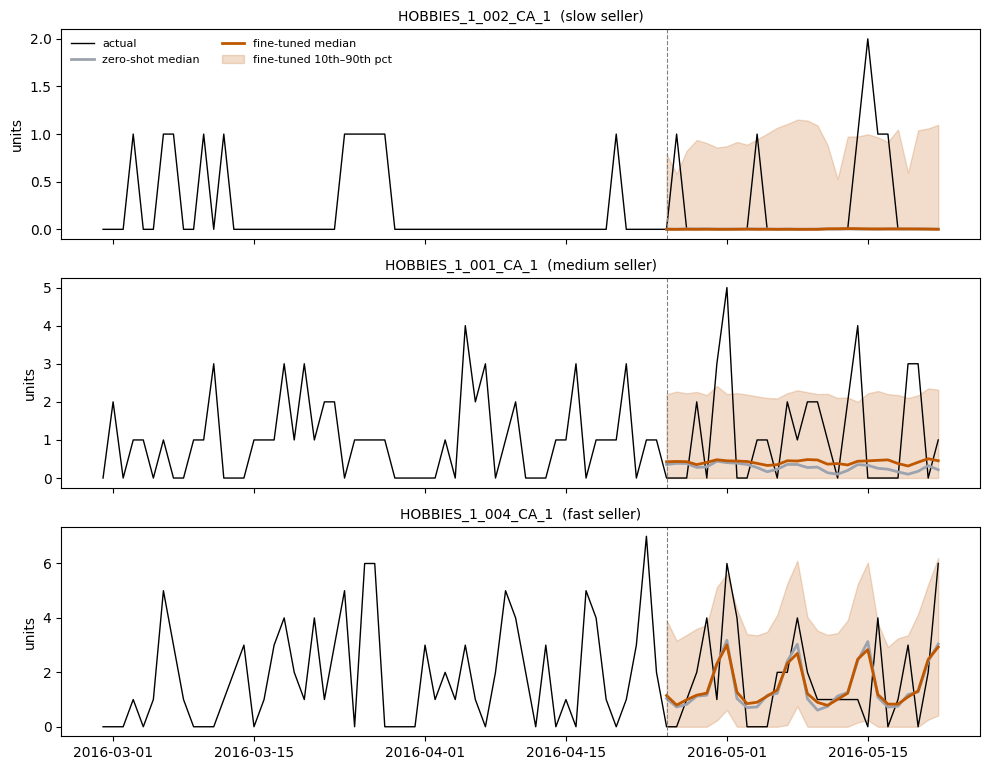

In [18]:
import matplotlib.pyplot as plt
wname = "test" if "test" in windows else list(windows)[-1]
p_ft, p_zs = f"{OUT_DIR}/{MODEL_NAME}_{wname}.parquet", f"{OUT_DIR}/chronos2_zs_{wname}.parquet"
ft = pd.read_parquet(p_ft); ft["unique_id"] = ft["unique_id"].astype(str)
zs = pd.read_parquet(p_zs) if os.path.exists(p_zs) else None
if zs is not None:
    zs["unique_id"] = zs["unique_id"].astype(str)
start, end = windows[wname]
static = pd.read_parquet(f"{DATA_DIR}/ca_static.parquet")
static["unique_id"] = static["unique_id"].astype(str)
pick = (static[static["unique_id"].isin(ft["unique_id"])]
        .groupby("sales_speed", observed=True)["unique_id"].first())

fig, axes = plt.subplots(len(pick), 1, figsize=(10, 2.6 * len(pick)), sharex=True)
for ax, (speed, uid) in zip(np.atleast_1d(axes), pick.items()):
    hist = df[(df["unique_id"] == uid) & (df["ds"] >= start - pd.Timedelta(days=56)) & (df["ds"] <= end)]
    f1 = ft[ft["unique_id"] == uid]
    ax.plot(hist["ds"], hist["y"], color="black", lw=1, label="actual")
    if zs is not None:
        f0 = zs[zs["unique_id"] == uid]
        ax.plot(f0["ds"], f0["forecast"], color="#9CA3AF", lw=2, label="zero-shot median")
    ax.plot(f1["ds"], f1["forecast"], color="#BF5700", lw=2, label="fine-tuned median")
    ax.fill_between(f1["ds"], f1["q0.1"], f1["q0.9"], color="#BF5700", alpha=0.2, label="fine-tuned 10th–90th pct")
    ax.axvline(start, color="grey", ls="--", lw=0.8)
    ax.set_title(f"{uid}  ({speed} seller)", fontsize=10); ax.set_ylabel("units")
np.atleast_1d(axes)[0].legend(frameon=False, ncol=2, fontsize=8)
plt.tight_layout()
os.makedirs(f"{DATA_DIR}/figures", exist_ok=True)
if not SAMPLE:
    plt.savefig(f"{DATA_DIR}/figures/12_chronos2_finetuned_examples.png", dpi=150, bbox_inches="tight")
plt.show()

## What to report back
Download this notebook (**File → Download → .ipynb**) with outputs into *Project Code*.
1. **Smoke test (`SAMPLE = True`):** did it finish without errors? Section 5's minutes per window tell us how long the full run will take.
2. **Full run (`SAMPLE = False`):** Section 6. Did fine-tuning lower the error vs. zero-shot, and by how much? Did totals move closer to 1.00?
3. Then re-run **05** so `chronos2_ft` appears in the official results table.